# Notebook 05: Pipe replacement planning

## 1. Objective

Use the trained XGBoost model to choose circular work units and their execution order. Compare plans using **construction costs plus estimated repair costs over 25 years**. Export the selected plan as `submissions/optimized_25_year.csv`.

## 2. Setup and data

In [1]:
from pathlib import Path
from itertools import combinations, product
import csv
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Circle
from scipy import sparse
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components, dijkstra
from IPython.display import display

project_dir = Path.cwd()
if project_dir.name == "nds":
    project_dir = project_dir.parent
data_dir = project_dir / "data"
results_dir = project_dir / "results" / "cost_optimization"
submission_dir = project_dir / "submissions"
results_dir.mkdir(parents=True, exist_ok=True)
submission_dir.mkdir(exist_ok=True)

### Planning settings
The risk factors are sensitivity checks around the fitted model, not confidence limits. All plans use the same settings.

In [2]:
start_year = 2027
years = np.arange(start_year, start_year + 25)
annual_budget = 10_000_000
surface_rates = {"grassland": 3, "farmland": 7, "swamp": 12,
                 "road": 17, "structure": 50, "water": 32}
risk_factors = [0.75, 1.0, 1.25]
random_seed = 440
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
model_dir = project_dir / "results" / "model_comparison"
model = joblib.load(model_dir / "best_model.joblib")
model_details = json.loads((model_dir / "best_model_details.json").read_text())
predictors = model_details["predictor_columns"]
assert predictors == ["adjusted_age", "network_rate_75m"]

### Load the pipe inventory and leak history
The inventory keeps original materials. In the planning state, pipes that leaked before 2027 are treated as replaced with polyurethane, as in the earlier project notebooks. We retain geometric coverage of all original iron and the eight unknown-material pipes so the exported file meets the conservative coverage interpretation.

In [3]:
pipes = pd.read_csv(data_dir / "pipes.csv").rename(columns={
    "Pipe ID": "pipe_id", "Lay date": "lay_date", "Material": "material",
    "Surface": "surface", "GPS x1": "x1", "GPS y1": "y1",
    "GPS x2": "x2", "GPS y2": "y2"
})
leaks = pd.read_csv(data_dir / "train.csv").rename(columns={
    "Pipe ID": "pipe_id", "Date": "leak_date"
})
pipes["lay_date"] = pd.to_datetime(pipes["lay_date"])
leaks["leak_date"] = pd.to_datetime(leaks["leak_date"])
first_leak = leaks.groupby("pipe_id")["leak_date"].min()
pipes["leak_year"] = pipes["pipe_id"].map(first_leak).dt.year
pipes["lay_year"] = pipes["lay_date"].dt.year
pipes["material"] = pipes["material"].fillna("unknown").str.strip().str.lower()
pipes["surface"] = pipes["surface"].fillna("unknown").str.strip().str.lower()

print(f"Pipes: {len(pipes):,}; recorded leak events: {len(leaks):,}")
display(pipes.head())

Pipes: 43,039; recorded leak events: 14,113


,pipe_id,lay_date,material,surface,x1,y1,x2,y2,leak_year,lay_year
0,P01001,1955-03-11,copper,grassland,"6,136.29","5,020.97","6,124.15","5,020.97",NaN,"1,955.00"
1,P01002,1971-09-19,cast iron,water,"6,512.35","4,147.58","6,536.59","4,201.94","2,023.00","1,971.00"
2,P01003,1971-09-18,cast iron,water,"6,536.59","4,201.94","6,518.42","4,201.93","2,024.00","1,971.00"
3,P01004,1982-05-22,cast iron,structure,"2,836.68","3,377.95","2,848.80","3,405.12",NaN,"1,982.00"
4,P01005,1971-07-03,cast iron,water,"5,117.28","4,272.91","5,126.37","4,297.16","2,024.00","1,971.00"


In [4]:
pipe_count = len(pipes)
starts = pipes[["x1", "y1"]].to_numpy()
ends = pipes[["x2", "y2"]].to_numpy()
midpoints = (starts + ends) / 2
lengths = np.hypot(ends[:, 0] - starts[:, 0], ends[:, 1] - starts[:, 1])
pipes["length_m"] = lengths
surfaces = pipes["surface"].to_numpy()
required = pipes["material"].isin(["cast iron", "gray iron", "wrought iron", "unknown"]).to_numpy()
live = ((pipes["material"] != "polyurethane") & pipes["leak_year"].isna()).to_numpy()
assert leaks["leak_date"].dt.year.max() == 2026
assert pipes["pipe_id"].is_unique and np.isfinite(np.vstack([starts, ends])).all()
assert pipes["surface"].isin(surface_rates).all()
assert leaks["pipe_id"].isin(pipes["pipe_id"]).all()
assert pipes["lay_year"].dropna().max() <= start_year
print(f"Coverage targets: {required.sum():,}; remaining targets: {(required & live).sum():,}")

Coverage targets: 38,463; remaining targets: 26,245


## 3. Estimate repair costs

Use the historical mean cost for each surface, shrinking it toward the overall mean with 20 pseudo-observations. The previous comparison favored this estimate over a material-and-surface estimate. Below we compare it with the overall mean using 2019–2024 for fitting and 2025–2026 for validation, then refit on all history. These years have already been used for development.

In [5]:
repair_history = leaks.merge(pipes[["pipe_id", "surface"]], on="pipe_id", validate="many_to_one")

def surface_costs(history):
    costs = history.groupby("surface")["Cost"].agg(["sum", "count"])
    return (costs["sum"] + 20 * history["Cost"].mean()) / (costs["count"] + 20)

cost_training = repair_history[repair_history["leak_date"].dt.year <= 2024]
cost_validation = repair_history[repair_history["leak_date"].dt.year >= 2025]
validation_predictions = pd.DataFrame({
    "Overall mean": cost_training["Cost"].mean(),
    "Surface mean": cost_validation["surface"].map(surface_costs(cost_training))
})
actual_costs = cost_validation["Cost"].to_numpy()
cost_validation_results = pd.DataFrame({
    "RMSE": np.sqrt(((validation_predictions - actual_costs[:, None])**2).mean()),
    "Predicted / actual total": validation_predictions.sum() / actual_costs.sum()
})
repair_cost = pipes["surface"].map(surface_costs(repair_history)).to_numpy()
assert np.isfinite(repair_cost).all() and (repair_cost > 0).all()
cost_validation_results.to_csv(results_dir / "repair_cost_validation.csv")
display(cost_validation_results)

,RMSE,Predicted / actual total
Overall mean,"134,235.45",1.09
Surface mean,"123,541.59",1.14


## 4. Predict annual leak risk

The model uses **adjusted age** and **75 m network leak rate**. 

### Build the network
Connect each pipe midpoint to its endpoint junctions using half its length as the edge distance.

In [6]:
pipe_count = len(pipes)
endpoint_coordinates = np.vstack([
    pipes[["x1", "y1"]].to_numpy(), pipes[["x2", "y2"]].to_numpy()
])
endpoint_pairs = cKDTree(endpoint_coordinates).query_pairs(0.04, output_type="ndarray")
endpoint_links = sparse.csr_matrix(
    (np.ones(2 * len(endpoint_pairs)),
     (np.concatenate([endpoint_pairs[:, 0], endpoint_pairs[:, 1]]),
      np.concatenate([endpoint_pairs[:, 1], endpoint_pairs[:, 0]]))),
    shape=(2 * pipe_count, 2 * pipe_count)
)
number_of_junctions, junction_ids = connected_components(endpoint_links)
print(f"Inferred junctions: {number_of_junctions:,}")

Inferred junctions: 42,570


In [7]:
midpoint_ids = number_of_junctions + np.arange(pipe_count)
edge_start = junction_ids
edge_end = np.concatenate([midpoint_ids, midpoint_ids])
half_lengths = np.tile(pipes["length_m"].to_numpy() / 2, 2)
number_of_nodes = number_of_junctions + pipe_count

pipe_graph = sparse.csr_matrix(
    (np.concatenate([half_lengths, half_lengths]),
     (np.concatenate([edge_start, edge_end]), np.concatenate([edge_end, edge_start]))),
    shape=(number_of_nodes, number_of_nodes)
)
print(f"Graph nodes: {number_of_nodes:,}")

Graph nodes: 85,609


### Find the 75 m neighbours
Calculate distances in batches to keep memory use manageable. Exclude each pipe from its own neighbourhood.

In [8]:
row_parts, column_parts, distance_parts = [], [], []
for start in range(0, pipe_count, 96):
    stop = min(start + 96, pipe_count)
    distances = dijkstra(pipe_graph, directed=False,
                         indices=midpoint_ids[start:stop], limit=75.01)[:, midpoint_ids]
    distances[np.arange(stop - start), np.arange(start, stop)] = np.inf
    nearby_rows, nearby_columns = np.where(np.isfinite(distances))
    row_parts.append(nearby_rows + start)
    column_parts.append(nearby_columns)
    distance_parts.append(distances[nearby_rows, nearby_columns].astype("float32"))

network_rows = np.concatenate(row_parts)
network_columns = np.concatenate(column_parts)
network_distances = np.concatenate(distance_parts)

keep = network_distances <= 75
network_neighbours = sparse.csr_matrix(
    (np.ones(keep.sum(), dtype="float32"), (network_rows[keep], network_columns[keep])),
    shape=(pipe_count, pipe_count)
)
print("Mean 75 m network neighbours:", round(network_neighbours.getnnz(axis=1).mean(), 1))

Mean 75 m network neighbours: 17.6


### Calculate calendar age
Use actual anniversary intervals, including February 29. Keep the same empirical 0.4-per-year adjustment used when fitting the model. Missing ages use the median from the prepared training data.

In [9]:
def age_on_january_first(dates, year):
    valid = dates.notna()
    dates = dates[valid]
    month = dates.dt.month.to_numpy()
    day = dates.dt.day.to_numpy()
    anniversary_year = np.where((month == 1) & (day == 1), year, year - 1)
    anniversaries = []
    for anniversary in [anniversary_year, anniversary_year + 1]:
        leap = (anniversary % 4 == 0) & ((anniversary % 100 != 0) | (anniversary % 400 == 0))
        anniversary_day = np.where((month == 2) & (day == 29) & ~leap, 28, day)
        anniversaries.append(pd.to_datetime({"year": anniversary, "month": month, "day": anniversary_day}))
    fraction = ((pd.Timestamp(year, 1, 1) - anniversaries[0]).dt.days
                / (anniversaries[1] - anniversaries[0]).dt.days).to_numpy()
    result = pd.Series(np.nan, index=valid.index)
    result.loc[valid] = anniversary_year - dates.dt.year.to_numpy() + fraction
    return result

### Prepare the initial model inputs
For 2027, the network rate uses observed 2026 events and at-risk exposure. The smoothing strength of 10 is inherited from Notebook 03.

In [10]:
training_data = pd.read_csv(data_dir / "model_training_data.csv")
training_medians = training_data[predictors].median()
annual_ages = []
for year in years:
    adjusted_age = age_on_january_first(pipes["lay_date"], year) + 0.4 * (year - 2020)
    annual_ages.append(adjusted_age.fillna(training_medians["adjusted_age"]).to_numpy())
annual_ages = np.array(annual_ages)
exposed_2026 = ((pipes["material"] != "polyurethane")
                & (pipes["leak_year"].isna() | (pipes["leak_year"] >= 2026))
                & (pipes["lay_year"].isna() | (pipes["lay_year"] <= 2026))).to_numpy(float)
events_2026 = (pipes["leak_year"] == 2026).to_numpy(float)
overall_rate = events_2026.sum() / exposed_2026.sum()
initial_network_rate = ((network_neighbours @ events_2026 + 10 * overall_rate)
                        / (network_neighbours @ exposed_2026 + 10))

### Project survival over 25 years
Each prediction is the probability of leaking during that year **conditional on still being unreplaced**. Survival is multiplied by `(1 − probability)` each year, so a pipe is charged for at most one first leak. Future network rates use expected previous-year leaks and exposure. They are fixed planning scenarios; they do not include changes in cascade risk caused by construction.

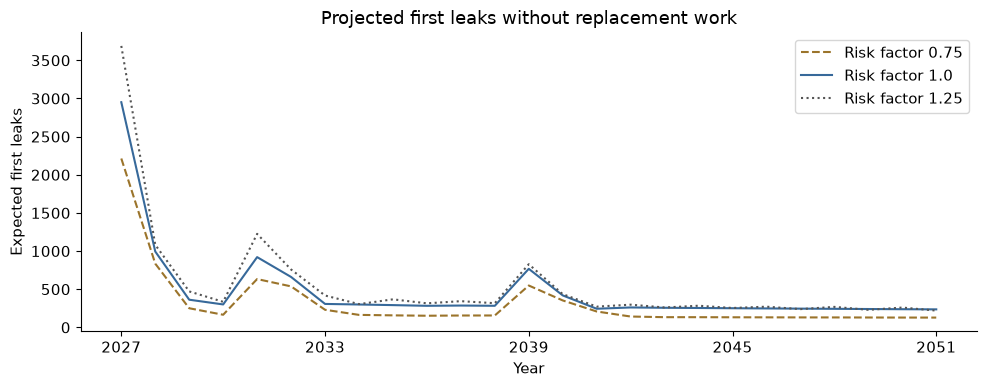

In [11]:
survival_scenarios = []
for factor in risk_factors:
    survival = np.zeros((26, pipe_count))
    survival[0] = live
    network_rate = initial_network_rate.copy()
    for t, year in enumerate(years):
        features = pd.DataFrame({"adjusted_age": annual_ages[t], "network_rate_75m": network_rate})
        probability = np.zeros(pipe_count)
        probability[live] = np.minimum(factor * model.predict_proba(features.loc[live, predictors])[:, 1], 0.95)
        expected_leaks = survival[t] * probability
        overall_rate = expected_leaks.sum() / max(survival[t].sum(), 1)
        network_rate = ((network_neighbours @ expected_leaks + 10 * overall_rate)
                        / (network_neighbours @ survival[t] + 10))
        survival[t + 1] = survival[t] * (1 - probability)
    survival_scenarios.append(survival)
survival_scenarios = np.array(survival_scenarios)
assert (np.diff(survival_scenarios, axis=1) <= 0).all()

forecast_summary = pd.DataFrame({"year": years})
for scenario, factor in enumerate(risk_factors):
    forecast_summary[f"Risk factor {factor}"] = -np.diff(survival_scenarios[scenario], axis=0).sum(axis=1)
forecast_summary.to_csv(results_dir / "risk_scenario_summary.csv", index=False)
ax = forecast_summary.set_index("year").plot(style=["--", "-", ":"], color=["#9b742b", "#37699a", "#555555"])
ax.set(title="Projected first leaks without replacement work", xlabel="Year", ylabel="Expected first leaks")
ax.set_xticks([2027, 2033, 2039, 2045, 2051])
plt.tight_layout()
plt.show()

## 5. Create candidate work units

Start with one circle per coverage target: midpoint as the center and half the pipe length as the radius. Add a 1 mm rounding margin. Then consider grouping each target with its four nearest eligible midpoint neighbours within 40 m, including copper/brass.

A straight pipe is wholly contained when **both endpoints** lie inside the circle. All contained pipes contribute their surface; all contained non-polyurethane pipes contribute replacement length.

In [12]:
target_rows = np.flatnonzero(required)
midpoint_tree = cKDTree(midpoints)

def contained_pipes(center, radius):
    nearby = np.array(midpoint_tree.query_ball_point(center, radius), dtype=int)
    inside = ((np.linalg.norm(starts[nearby] - center, axis=1) <= radius)
              & (np.linalg.norm(ends[nearby] - center, axis=1) <= radius))
    return nearby[inside]

_, neighbours = midpoint_tree.query(midpoints[target_rows], k=5, distance_upper_bound=40)
pair_set = set()
for pipe_row, nearby_rows in zip(target_rows, neighbours):
    for neighbour in nearby_rows:
        if neighbour < pipe_count and neighbour != pipe_row and (required[neighbour] or live[neighbour]):
            pair_set.add(tuple(sorted((int(pipe_row), int(neighbour)))))
pipe_pairs = np.array(sorted(pair_set))
print(f"Nearby pairs to consider: {len(pipe_pairs):,}")

Nearby pairs to consider: 88,780


### Fit a circle around two pipes
A smallest circle is determined by two or three boundary endpoints. Try their candidate centers, measure the radius needed to include all four endpoints, and keep the smallest. Coordinates are shifted near zero for numerical accuracy.

In [13]:
def pair_circle(first_pipe, second_pipe):
    points = np.vstack([starts[first_pipe], ends[first_pipe], starts[second_pipe], ends[second_pipe]])
    origin = points.mean(axis=0)
    points = points - origin
    centers = [(first + second) / 2 for first, second in combinations(points, 2)]
    for first, second, third in combinations(points, 3):
        matrix = 2 * np.array([second - first, third - first])
        if abs(np.linalg.det(matrix)) > 1e-10:
            squared_distances = np.array([second @ second - first @ first,
                                          third @ third - first @ first])
            centers.append(np.linalg.solve(matrix, squared_distances))
    radii = [np.linalg.norm(points - center, axis=1).max() for center in centers]
    best = np.argmin(radii)
    return [*(centers[best] + origin), radii[best] + 0.001]

individual_circles = np.column_stack([midpoints, lengths / 2 + 0.001])
grouped_circles = np.array([pair_circle(first, second) for first, second in pipe_pairs])
geometry = np.vstack([individual_circles, grouped_circles]).round(8)

### Price the circles
`100 + (surface rate × area)^0.85 + 200 × non-polyurethane length`

In [14]:
circle_members = []
fixed_cost = np.zeros(len(geometry))
initial_cost = np.zeros(len(geometry))
for circle_id, (x, y, radius) in enumerate(geometry):
    members = contained_pipes([x, y], radius)
    circle_members.append(members)
    rate = sum(surface_rates[surface] for surface in set(surfaces[members]))
    fixed_cost[circle_id] = 100 + (rate * np.pi * radius**2)**0.85
    initial_cost[circle_id] = fixed_cost[circle_id] + 200 * lengths[members[live[members]]].sum()
assert (initial_cost < annual_budget).all()
for pair_number, pair in enumerate(pipe_pairs):
    assert np.isin(pair, circle_members[pipe_count + pair_number]).all()
print(f"Candidate circles: {len(geometry):,}")

Candidate circles: 131,819


### Compare grouping choices
Compare separate circles with each grouped alternative, counting shared replacement length only once. Additional excavation can be worthwhile if it prevents expensive leaks on incidental non-iron pipes. Test three weights for this extra repair benefit: 0, 0.5 and 1. Greedily accept pairs that do not share a required owner, then retain individual circles for the other targets.

In [15]:
lifetime_repair_risk = (live - survival_scenarios[:, -1].mean(axis=0)) * repair_cost
construction_savings = np.zeros(len(pipe_pairs))
extra_repair_benefit = np.zeros(len(pipe_pairs))
for pair_number, pair in enumerate(pipe_pairs):
    owners = pair[required[pair]]
    separate_members = np.unique(np.concatenate([circle_members[owner] for owner in owners]))
    separate_cost = fixed_cost[owners].sum() + 200 * lengths[separate_members[live[separate_members]]].sum()
    group_id = pipe_count + pair_number
    construction_savings[pair_number] = separate_cost - initial_cost[group_id]
    members = circle_members[group_id]
    extra = members[live[members] & ~required[members] & ~np.isin(members, separate_members)]
    extra_repair_benefit[pair_number] = lifetime_repair_risk[extra].sum()

def select_groups(repair_weight):
    benefit = construction_savings + repair_weight * extra_repair_benefit
    used = np.zeros(pipe_count, dtype=bool)
    selected = []
    for pair_number in np.argsort(-benefit, kind="stable"):
        if benefit[pair_number] <= 0:
            break
        owners = pipe_pairs[pair_number][required[pipe_pairs[pair_number]]]
        if not used[owners].any():
            selected.append(pipe_count + pair_number)
            used[owners] = True
    return np.array(selected + target_rows[~used[target_rows]].tolist())

circle_sets = {"Individual": target_rows}
for weight in [0.0, 0.5, 1.0]:
    circle_sets[f"Grouped {weight}"] = select_groups(weight)

## 6. Optimize the 25-year plan

### Create a budgeted schedule

Add the annual allocation to the available balance. Execute jobs in order and carry unused funds forward; if the next job is unaffordable, wait for the following year. Drop circles that add no required coverage.

This scheduling pass assumes no future leaks, so it budgets for the maximum replacement length. It therefore remains affordable when future leaks have already replaced some pipes. Fixed earthwork is charged for every retained circle, including one that later contains only polyurethane.

In [16]:
def create_schedule(order):
    covered = np.zeros(pipe_count, dtype=bool)
    active = live.copy()
    replacement_year = np.full(pipe_count, 25, dtype=int)
    budget = annual_budget * 100
    year_index = 0
    jobs = []
    for circle_id in order:
        members = circle_members[circle_id]
        if not (required[members] & ~covered[members]).any():
            continue
        replacing = members[active[members]]
        cost = round((fixed_cost[circle_id] + 200 * lengths[replacing].sum()) * 100)
        while cost > budget:
            year_index += 1
            if year_index == 25:
                return None, None
            budget += annual_budget * 100
        budget -= cost
        replacement_year[members] = np.minimum(replacement_year[members], year_index)
        covered[members] = True
        active[replacing] = False
        jobs.append({"circle_id": circle_id, "year": int(years[year_index]), "cost_cents": cost})
    assert covered[required].all() and not (active & required).any()
    return pd.DataFrame(jobs), replacement_year

### Score the complete project window
For each pipe, use its scheduled replacement year, or the end of 2051 if it is never scheduled. Expected repair cost equals the chance of leaking before that point times the estimated repair cost. Expected construction length is charged only if the pipe survives until replacement. Add all fixed excavation costs. Average the three sensitivity scenarios equally.

In [17]:
def project_cost(schedule, replacement_year):
    survival_before_work = survival_scenarios[:, replacement_year, np.arange(pipe_count)]
    scheduled = replacement_year < 25
    construction = (fixed_cost[schedule["circle_id"]].sum()
                    + (survival_before_work[:, scheduled] * 200 * lengths[scheduled]).sum(axis=1))
    repairs = ((live - survival_before_work) * repair_cost).sum(axis=1)
    return pd.DataFrame({"Risk factor": risk_factors, "Construction": construction,
                         "Repairs": repairs, "Total": construction + repairs})

### Prepare ordering scores
Test oldest-first and risk/cost rankings. A ranking uses the expected net cost of delaying replacement for 1, 3, 8 or 25 years. Dividing by construction cost to the power 0, 0.5 or 1 tests different preferences for cheaper jobs. **Every candidate is evaluated over the full 25 years**, regardless of its ranking horizon.

In [18]:
remaining_target = np.array([(required[members] & live[members]).any() for members in circle_members])
circle_scores = {}
for horizon in [1, 3, 8, 25]:
    failure_probability = live - survival_scenarios[:, horizon].mean(axis=0)
    delay_cost = failure_probability * (repair_cost - 200 * lengths)
    circle_scores[horizon] = np.array([delay_cost[members].sum() for members in circle_members])
owner_rows = np.concatenate([np.arange(pipe_count), pipe_pairs[:, 0]])
circle_dates = pipes.loc[owner_rows, "lay_date"].fillna(pd.Timestamp("2100-01-01")).to_numpy()
settings = [(None, None)] + list(product([1, 3, 8, 25], [0.0, 0.5, 1.0]))

### Compare candidates and select the lowest-cost feasible plan
This is a parameter comparison like a model-selection table: four circle sets × thirteen orderings. Keep plans that finish within the project window, choose the lowest mean total cost, and break ties using the highest scenario cost. This finite search does not prove global optimality.

In [19]:
search_rows = []
candidate_plans = {}
for group_name, circle_ids in circle_sets.items():
    for horizon, cost_power in settings:
        ranking = pd.DataFrame({"circle_id": circle_ids, "remaining_target": remaining_target[circle_ids]})
        if horizon is None:
            ranking["score"] = circle_dates[circle_ids]
            ascending = [False, True, True]
            name = f"{group_name}: oldest first"
        else:
            ranking["score"] = circle_scores[horizon][circle_ids] / initial_cost[circle_ids]**cost_power
            ascending = [False, False, True]
            name = f"{group_name}: {horizon} years, cost power {cost_power}"
        order = ranking.sort_values(["remaining_target", "score", "circle_id"], ascending=ascending)["circle_id"]
        schedule, replacement_year = create_schedule(order)
        if schedule is None:
            continue
        costs = project_cost(schedule, replacement_year)
        candidate_plans[name] = (schedule, replacement_year)
        search_rows.append({"Candidate": name, "Work units": len(schedule),
                            "Completion year": schedule["year"].max(),
                            "Construction without future leaks": schedule["cost_cents"].sum() / 100,
                            "Expected construction": costs["Construction"].mean(),
                            "Expected repairs": costs["Repairs"].mean(),
                            "Expected total": costs["Total"].mean(), "Highest scenario total": costs["Total"].max()})
search_results = pd.DataFrame(search_rows).sort_values(["Expected total", "Highest scenario total", "Candidate"])
best_name = search_results.iloc[0]["Candidate"]
best_schedule, best_replacement_year = candidate_plans[best_name]
baseline_schedule, baseline_replacement_year = candidate_plans["Individual: oldest first"]
search_results.to_csv(results_dir / "search_results.csv", index=False)
print("Selected:", best_name)
display(search_results[["Candidate", "Work units", "Completion year", "Expected total"]].head(6))

Selected: Grouped 0.5: 8 years, cost power 1.0


,Candidate,Work units,Completion year,Expected total
35,"Grouped 0.5: 8 years, cost power 1.0",26075,2044,"200,648,842.98"
48,"Grouped 1.0: 8 years, cost power 1.0",26075,2044,"201,061,125.87"
22,"Grouped 0.0: 8 years, cost power 1.0",26071,2043,"201,425,566.30"
34,"Grouped 0.5: 8 years, cost power 0.5",24390,2043,"201,728,661.88"
47,"Grouped 1.0: 8 years, cost power 0.5",24383,2043,"201,998,093.16"
21,"Grouped 0.0: 8 years, cost power 0.5",24387,2043,"202,513,561.25"


## 7. Evaluate the selected plan

First compare expected construction and repair costs. Then replay the selected plan and baseline with identical random future leaks. These comparisons evaluate the planning model; they are not official competition scores.

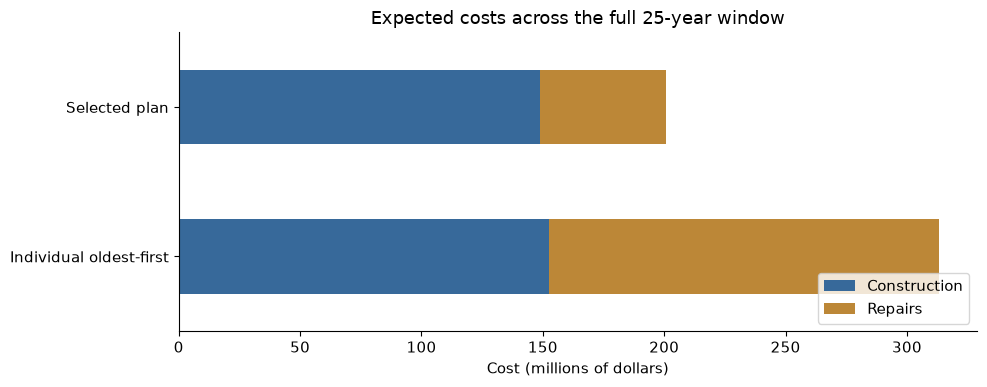

,Construction,Repairs,Total
Individual oldest-first,"152,646,008.44","160,551,684.88","313,197,693.32"
Selected plan,"148,684,937.70","51,963,905.29","200,648,842.98"


In [20]:
comparison = pd.DataFrame({
    "Individual oldest-first": project_cost(baseline_schedule, baseline_replacement_year)[["Construction", "Repairs"]].mean(),
    "Selected plan": project_cost(best_schedule, best_replacement_year)[["Construction", "Repairs"]].mean()
}).T
comparison["Total"] = comparison.sum(axis=1)
ax = (comparison[["Construction", "Repairs"]] / 1_000_000).plot.barh(stacked=True, color=["#37699a", "#bc8737"])
ax.set(title="Expected costs across the full 25-year window", xlabel="Cost (millions of dollars)", ylabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
display(comparison)

### Replay annual budgets and leaks
Execute work at the start of each year, then charge for first leaks in pipes that remain active. A leaking pipe becomes polyurethane. Repair costs vary using historical within-surface cost ratios, which retain the large-cost tail. Use the same first-leak times and repair-cost draws for both plans. Construction can move earlier when leaks reduce replacement length. The projected network hazards remain fixed during replay.

In [21]:
def replay_plan(schedule, failure_year, repair_amount):
    active = live.copy()
    order = schedule["circle_id"].to_numpy()
    budget = 0
    construction = 0
    repairs = 0.0
    position = 0
    completion_year = None
    for t, year in enumerate(years):
        budget += annual_budget * 100
        while position < len(order):
            circle_id = order[position]
            members = circle_members[circle_id]
            replacing = members[active[members]]
            cost = round((fixed_cost[circle_id] + 200 * lengths[replacing].sum()) * 100)
            if cost > budget:
                break
            budget -= cost
            construction += cost
            active[replacing] = False
            position += 1
            if position == len(order):
                completion_year = int(year)
        leaking = active & (failure_year == t)
        repairs += repair_amount[leaking].sum()
        active[leaking] = False
        assert construction <= (t + 1) * annual_budget * 100
    assert position == len(order) and not (active & required).any()
    return {"Construction": construction / 100, "Repairs": repairs,
            "Total": construction / 100 + repairs, "Completion year": completion_year}

### Validate the budget replay
With no future leaks, replay must reproduce the conservative schedule exactly. This checks queue execution, carryover and overlapping replacement charges.

In [22]:
for schedule in [baseline_schedule, best_schedule]:
    replay = replay_plan(schedule, np.full(pipe_count, 25), np.zeros(pipe_count))
    assert replay["Construction"] == schedule["cost_cents"].sum() / 100
    assert replay["Completion year"] == schedule["year"].max()
print("No-leak replay matches both schedules.")

No-leak replay matches both schedules.


### Run the paired simulations
Freeze the selected plan before this check. Run 24 seeds for each of the three risk scenarios: 72 paired worlds. Polyurethane has zero risk and each original pipe can have only one first leak. This does not reproduce the full PDF cascading/clustered leak mechanism, whose parameters are not supplied.

In [23]:
cost_ratios = {surface: group["Cost"].to_numpy() / group["Cost"].mean()
               for surface, group in repair_history.groupby("surface")}
simulation_rows = []
for scenario, factor in enumerate(risk_factors):
    cumulative_failure = live - survival_scenarios[scenario, 1:]
    for seed in range(24):
        rng = np.random.default_rng(random_seed + 10_000 + seed)
        failure_year = (rng.random(pipe_count)[None, :] > cumulative_failure).sum(axis=0)
        failure_year[~live] = 25
        repair_amount = repair_cost.copy()
        for surface, ratios in cost_ratios.items():
            rows = np.flatnonzero(surfaces == surface)
            repair_amount[rows] *= rng.choice(ratios, len(rows))
        for name, schedule in [("Baseline", baseline_schedule), ("Selected", best_schedule)]:
            result = replay_plan(schedule, failure_year, repair_amount)
            simulation_rows.append({"Plan": name, "Risk factor": factor, "Seed": seed, **result})
simulations = pd.DataFrame(simulation_rows)
simulations.to_csv(results_dir / "simulation_results.csv", index=False)
paired_costs = simulations.pivot(index=["Risk factor", "Seed"], columns="Plan", values="Total")
paired_costs["Savings"] = paired_costs["Baseline"] - paired_costs["Selected"]
paired_costs.to_csv(results_dir / "paired_simulation_savings.csv")
display(simulations.groupby(["Plan", "Risk factor"])[["Construction", "Repairs", "Total"]].mean())
print(f"Mean paired simulated savings: {paired_costs['Savings'].mean():,.0f} dollars")

Construction        Repairs          Total
Plan     Risk factor                                             
Baseline 0.75        161,677,444.77 111,269,844.07 272,947,288.84
         1.00        156,808,808.33 144,085,317.97 300,894,126.30
         1.25        152,059,729.60 171,364,940.14 323,424,669.73
Selected 0.75        155,271,111.78  35,789,248.89 191,060,360.67
         1.00        150,056,513.40  49,358,710.58 199,415,223.98
         1.25        145,488,684.49  60,254,096.15 205,742,780.64

Mean paired simulated savings: 100,349,240 dollars


### Check the construction budget and inspect one work unit
The conservative schedule does not rely on any future leaks. Cumulative construction spending must stay below cumulative allocations throughout the project.

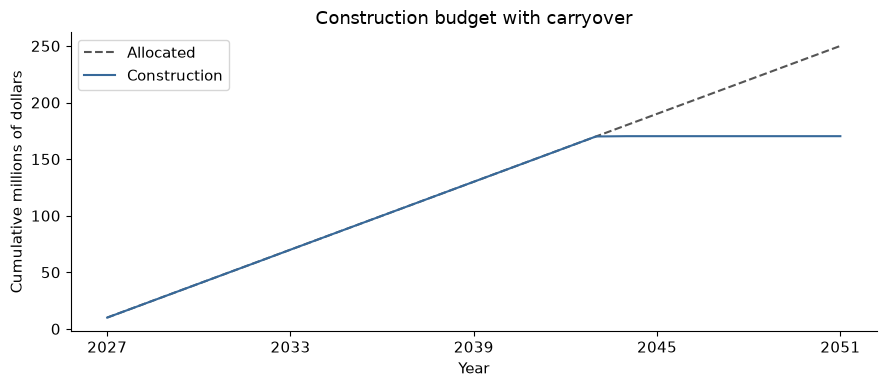

In [24]:
annual = pd.DataFrame({"year": years})
annual_costs = best_schedule.groupby("year")["cost_cents"].sum() / 100
annual["construction"] = annual["year"].map(annual_costs).fillna(0)
annual["cumulative_construction"] = annual["construction"].cumsum()
annual["cumulative_allocation"] = np.arange(1, 26) * annual_budget
annual["budget_remaining"] = annual["cumulative_allocation"] - annual["cumulative_construction"]
assert (annual["budget_remaining"] >= 0).all()
annual.to_csv(results_dir / "annual_budget_no_future_leaks.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(years, annual["cumulative_allocation"] / 1e6, "--", color="#555555", label="Allocated")
ax.plot(years, annual["cumulative_construction"] / 1e6, color="#37699a", label="Construction")
ax.set(title="Construction budget with carryover", xlabel="Year", ylabel="Cumulative millions of dollars")
ax.set_xticks([2027, 2033, 2039, 2045, 2051])
ax.legend()
plt.tight_layout()
plt.show()

### Inspect a grouped work unit
Blue segments are wholly contained; grey segments are nearby pipes. The orange circle is the earthwork boundary.

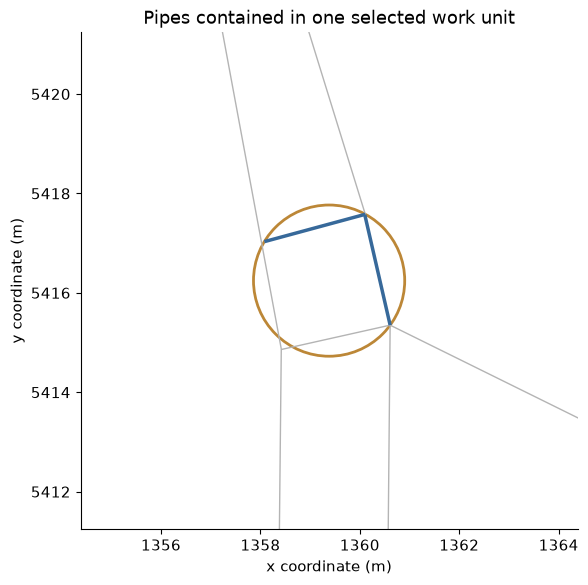

In [25]:
fig, ax = plt.subplots(figsize=(6, 6))
selected_group_ids = best_schedule.loc[best_schedule["circle_id"] >= pipe_count, "circle_id"]
example_id = int(selected_group_ids.iloc[0] if len(selected_group_ids) else best_schedule.iloc[0]["circle_id"])
x, y, radius = geometry[example_id]
members = circle_members[example_id]
nearby = midpoint_tree.query_ball_point([x, y], max(2 * radius, 20))
segments = np.stack([starts, ends], axis=1)
ax.add_collection(LineCollection(segments[nearby], colors="#b4b4b4", linewidths=1))
ax.add_collection(LineCollection(segments[members], colors="#37699a", linewidths=2.5))
ax.add_patch(Circle((x, y), radius, fill=False, color="#bc8737", linewidth=2))
zoom = max(1.4 * radius, 5)
ax.set(xlim=(x - zoom, x + zoom), ylim=(y - zoom, y + zoom),
            title="Pipes contained in one selected work unit", xlabel="x coordinate (m)", ylabel="y coordinate (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 8. Export the selected plan

Only center coordinates and radius belong in the submission. Write the selected order without a header. Keep scheduling details in the results folder. Reopen the CSV and verify coverage using endpoint searches independent of candidate generation.

In [26]:
submission_path = submission_dir / "optimized_25_year.csv"
with submission_path.open("w", newline="") as file:
    writer = csv.writer(file, lineterminator="\n")
    for circle_id in best_schedule["circle_id"]:
        x, y, radius = geometry[circle_id]
        writer.writerow([f"({x:.8f}, {y:.8f})", f"{radius:.8f}"])

endpoint_tree = cKDTree(starts)
covered = np.zeros(pipe_count, dtype=bool)
row_count = 0
with submission_path.open(newline="") as file:
    for center, radius in csv.reader(file):
        x, y = map(float, center.strip("()").split(","))
        radius = float(radius)
        assert np.isfinite([x, y, radius]).all() and radius > 0
        nearby = np.array(endpoint_tree.query_ball_point([x, y], radius), dtype=int)
        contained = nearby[np.hypot(ends[nearby, 0] - x, ends[nearby, 1] - y) <= radius]
        covered[contained] = True
        row_count += 1
assert covered[required].all() and row_count == len(best_schedule)
assert best_schedule["year"].max() <= min(years[-1], 2052)
print(f"Saved {row_count:,} work units; uncovered required pipes: {(required & ~covered).sum()}")

Saved 26,075 work units; uncovered required pipes: 0


### Save the results
The schedule uses the conservative no-future-leak dates. Simulated execution dates may be earlier. Estimated savings depend on the forecast and evaluation settings above.

In [27]:
schedule_output = best_schedule.copy()
schedule_output[["x", "y", "radius"]] = geometry[best_schedule["circle_id"]]
schedule_output["construction_cost"] = schedule_output.pop("cost_cents") / 100
schedule_output.to_csv(results_dir / "selected_schedule.csv", index=False)
pd.DataFrame({"pipe_id": pipes["pipe_id"], "required_coverage": required, "active_at_start": live,
              "estimated_repair_cost": repair_cost,
              "planned_year": np.where(best_replacement_year < 25, start_year + best_replacement_year, np.nan),
              "central_lifetime_leak_probability_without_work": live - survival_scenarios[1, -1]
              }).to_csv(results_dir / "pipe_planning_details.csv", index=False)
summary = {"selected_candidate": best_name, "years": [int(years[0]), int(years[-1])],
           "annual_budget": annual_budget, "budget_carryover": True, "work_units": row_count,
           "required_pipes": int(required.sum()), "uncovered_required_pipes": int((required & ~covered).sum()),
           "no_future_leak_construction": float(best_schedule["cost_cents"].sum() / 100),
           "no_future_leak_completion_year": int(best_schedule["year"].max()),
           "selected_mean_expected_total": float(comparison.loc["Selected plan", "Total"]),
           "baseline_mean_expected_total": float(comparison.loc["Individual oldest-first", "Total"]),
           "mean_paired_simulated_savings": float(paired_costs["Savings"].mean()),
           "candidate_plans_evaluated": len(search_results), "paired_simulation_worlds": len(paired_costs),
           "risk_factors": risk_factors, "source": "StarKingdom.pdf, pages 5–10; user-confirmed carryover",
           "evaluation_settings": ["Distinct surface rates summed", "Construction before annual leaks",
                                   "Repair costs separate from construction allocation", "Fixed projected hazards during replay"],
           "status": "Model-based planning estimate; not an official score or global optimum"}
(results_dir / "summary.json").write_text(json.dumps(summary, indent=2))
display(pd.Series({"Work units": row_count, "Completion year without future leaks": summary["no_future_leak_completion_year"],
                   "Construction without future leaks": summary["no_future_leak_construction"],
                   "Mean expected total project cost": summary["selected_mean_expected_total"],
                   "Uncovered required pipes": summary["uncovered_required_pipes"]}).to_frame("Selected plan"))
print("Submission:", submission_path)

,Selected plan
Work units,"26,075.00"
Completion year without future leaks,"2,044.00"
Construction without future leaks,"170,261,614.79"
Mean expected total project cost,"200,648,842.98"
Uncovered required pipes,0.00


Submission: /Users/simondoan/Documents/SFU/STAT 440/Project/P1/submissions/optimized_25_year.csv
